In [1]:
#import required packages and classes
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt   
import warnings
warnings.filterwarnings('ignore')

In [2]:
#loading & dislpaying Google 2019 cloud traces dataset
dataset = pd.read_csv("Dataset/borg_traces_data.csv")
dataset

,Unnamed: 0,time,instance_events_type,collection_id,scheduling_class,collection_type,priority,alloc_collection_id,instance_index,machine_id,...,assigned_memory,page_cache_memory,cycles_per_instruction,memory_accesses_per_instruction,sample_rate,cpu_usage_distribution,tail_cpu_usage_distribution,cluster,event,failed
0,11,723622816016,1,346556401280,1,0,103,0,8880,19641579566,...,0.010422,2.861023e-06,0.998315,0.002872,1.0,[0.00000000e+00 0.00000000e+00 0.00000000e+00 ...,[0.00190163 0.00190163 0.00190163 0.00190163 0...,6,EVICT,0
1,18,296066697739,1,784245858759,1,0,105,0,2198,5567221068,...,0.014969,1.983643e-04,NaN,NaN,1.0,[0.00793457 0.00805664 0.00813293 0.00820923 0...,[0.00961304 0.00967407 0.00975037 0.00982666 0...,4,EVICT,0
2,84,723622816016,1,346556401280,1,0,103,0,11661,78094657005,...,0.010422,2.861023e-06,0.998315,0.002872,1.0,[0.00000000e+00 0.00000000e+00 0.00000000e+00 ...,[0.00190163 0.00190163 0.00190163 0.00190163 0...,6,EVICT,0
3,123,723622816016,1,346556401280,1,0,103,0,16013,40273654136,...,0.010422,2.861023e-06,0.998315,0.002872,1.0,[0.00000000e+00 0.00000000e+00 0.00000000e+00 ...,[0.00190163 0.00190163 0.00190163 0.00190163 0...,6,EVICT,0
4,132,1303283406220,1,330587172974,2,1,101,0,2238,1579782802,...,0.032654,2.155304e-03,NaN,NaN,1.0,[0.00022125 0.00067806 0.00880432 0.01254272 0...,[0.04968262 0.05053711 0.05126953 0.05206299 0...,1,EVICT,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15946,19634,2308991217417,3,36376035925,3,0,200,36376033673,4695,230276569080,...,0.000000,2.870560e-04,2.227257,0.021485,1.0,[0.00047207 0.00068378 0.00074196 0.00078869 0...,[0.00121498 0.00124168 0.00126839 0.00130653 0...,2,FINISH,0
15947,19646,1930587759074,3,236368073537,0,0,0,0,7083,154736860318,...,0.002605,1.907349e-06,NaN,NaN,1.0,[],[],5,FINISH,0
15948,19648,2077391835991,3,105142593258,2,0,200,0,1312,3678203094,...,0.003242,2.355576e-04,2.207813,0.011707,1.0,[0.00310516 0.00337219 0.00353241 0.00367737 0...,[0.00526428 0.00534058 0.00541687 0.00563812 0...,7,FINISH,0
15949,19654,1087758274431,3,14423004927,2,0,0,0,1328,17006889400,...,0.000196,9.536743e-07,2.008303,0.007136,1.0,[3.52859497e-05 5.05447388e-05 9.44137573e-05 ...,[0.00038242 0.00038624 0.00039005 0.00039387 0...,5,FINISH,0


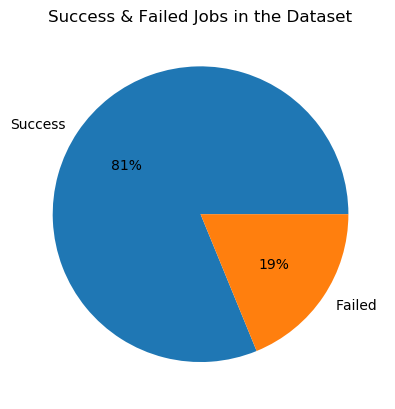

In [3]:
#Type of customers who is cancelling most tickets
labels, count = np.unique(dataset['failed'], return_counts=True)
labels = ['Success', 'Failed']
plt.pie(count, labels = labels, autopct='%.0f%%')
plt.title("Success & Failed Jobs in the Dataset")
plt.show()

In [4]:
#displaying failed and successful jobs in different clusters
success = dataset.loc[dataset['failed'] == 0]
failed = dataset.loc[dataset['failed'] == 1]
success = success.groupby(['cluster'])['failed'].count().reset_index(name="Successful Jobs")
failed = failed.groupby(['cluster'])['failed'].count().reset_index(name="Failed Jobs")
success['Failed Jobs'] = failed['Failed Jobs']
success

,cluster,Successful Jobs,Failed Jobs
0,1,1719,274
1,2,1057,331
2,3,2191,389
3,4,2114,414
4,5,864,454
5,6,3008,398
6,7,1045,399
7,8,953,341


In [5]:
#displaying failed and successful jobs in different scheduling schemes
success = dataset.loc[dataset['failed'] == 0]
failed = dataset.loc[dataset['failed'] == 1]
success = success.groupby(['scheduling_class'])['failed'].count().reset_index(name="Successful Jobs")
failed = failed.groupby(['scheduling_class'])['failed'].count().reset_index(name="Failed Jobs")
success['Failed Jobs'] = failed['Failed Jobs']
success

,scheduling_class,Successful Jobs,Failed Jobs
0,0,2552,600
1,1,5063,766
2,2,5191,1021
3,3,145,613


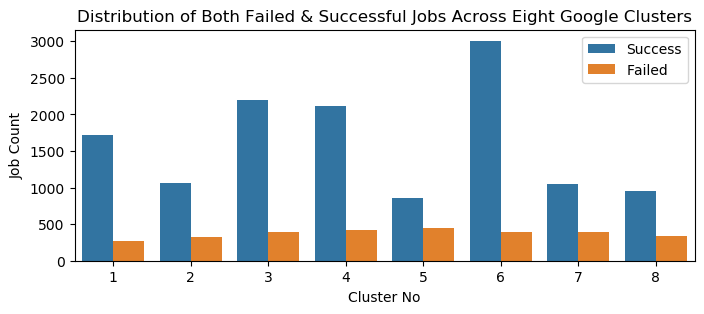

In [6]:
#Distribution of Both Failed & Successful Jobs Across Eight Google Clusters
data = dataset.groupby(["cluster",'failed'])['failed'].size().reset_index(name='Count')
data.loc[data["failed"] == 0, "failed"] = "Success"
data.loc[data["failed"] == 1, "failed"] = "Failed"
plt.figure(figsize=(8, 3))
sns.barplot(x='cluster', y='Count', hue='failed', data=data)
plt.title("Distribution of Both Failed & Successful Jobs Across Eight Google Clusters")
plt.xlabel('Cluster No')
plt.ylabel('Job Count')
plt.legend()
plt.show()

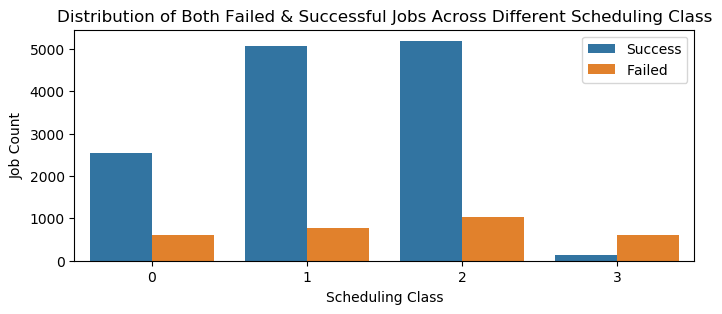

In [7]:
#Distribution of Both Failed & Successful Jobs Across scheduling_class
data = dataset.groupby(["scheduling_class",'failed'])['failed'].size().reset_index(name='Count')
data.loc[data["failed"] == 0, "failed"] = "Success"
data.loc[data["failed"] == 1, "failed"] = "Failed"
plt.figure(figsize=(8, 3))
sns.barplot(x='scheduling_class', y='Count', hue='failed', data=data)
plt.title("Distribution of Both Failed & Successful Jobs Across Different Scheduling Class")
plt.xlabel('Scheduling Class')
plt.ylabel('Job Count')
plt.legend()
plt.show()

In [8]:
#dataset processing to convert non-numeric data to numeric data and then replace misisng values with mean
#drop irrelevant columns
dataset.drop(['Unnamed: 0','user', 'tail_cpu_usage_distribution', 'resource_request', 'start_after_collection_ids'], axis = 1,inplace=True)
label_encoder = []
columns = dataset.columns
types = dataset.dtypes.values
for j in range(len(types)):
    name = types[j]
    if name == 'object': #finding column with object type
        le = LabelEncoder()
        dataset[columns[j]] = pd.Series(le.fit_transform(dataset[columns[j]].astype(str)))#encode all str columns to numeric
        label_encoder.append([columns[j], le])
dataset.fillna(dataset.mean(), inplace = True)
failed = dataset['failed']
dataset.drop(['failed'], axis = 1,inplace=True)
dataset.fillna(dataset.mean(), inplace = True)#replace missing values with 0
dataset

,time,instance_events_type,collection_id,scheduling_class,collection_type,priority,alloc_collection_id,instance_index,machine_id,constraint,...,maximum_usage,random_sample_usage,assigned_memory,page_cache_memory,cycles_per_instruction,memory_accesses_per_instruction,sample_rate,cpu_usage_distribution,cluster,event
0,723622816016,1,346556401280,1,0,103,0,8880,19641579566,0,...,1271,802,0.010422,2.861023e-06,0.998315,0.002872,1.0,47,6,0
1,296066697739,1,784245858759,1,0,105,0,2198,5567221068,8,...,1415,919,0.014969,1.983643e-04,1.861859,0.008631,1.0,1320,4,0
2,723622816016,1,346556401280,1,0,103,0,11661,78094657005,0,...,1271,802,0.010422,2.861023e-06,0.998315,0.002872,1.0,47,6,0
3,723622816016,1,346556401280,1,0,103,0,16013,40273654136,0,...,1271,802,0.010422,2.861023e-06,0.998315,0.002872,1.0,47,6,0
4,1303283406220,1,330587172974,2,1,101,0,2238,1579782802,4,...,2041,1202,0.032654,2.155304e-03,1.861859,0.008631,1.0,520,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15946,2308991217417,3,36376035925,3,0,200,36376033673,4695,230276569080,16,...,553,443,0.000000,2.870560e-04,2.227257,0.021485,1.0,756,2,2
15947,1930587759074,3,236368073537,0,0,0,0,7083,154736860318,8,...,21,0,0.002605,1.907349e-06,1.861859,0.008631,1.0,2073,5,2
15948,2077391835991,3,105142593258,2,0,200,0,1312,3678203094,0,...,1325,782,0.003242,2.355576e-04,2.207813,0.011707,1.0,1210,7,2
15949,1087758274431,3,14423004927,2,0,0,0,1328,17006889400,0,...,230,108,0.000196,9.536743e-07,2.008303,0.007136,1.0,1591,5,2


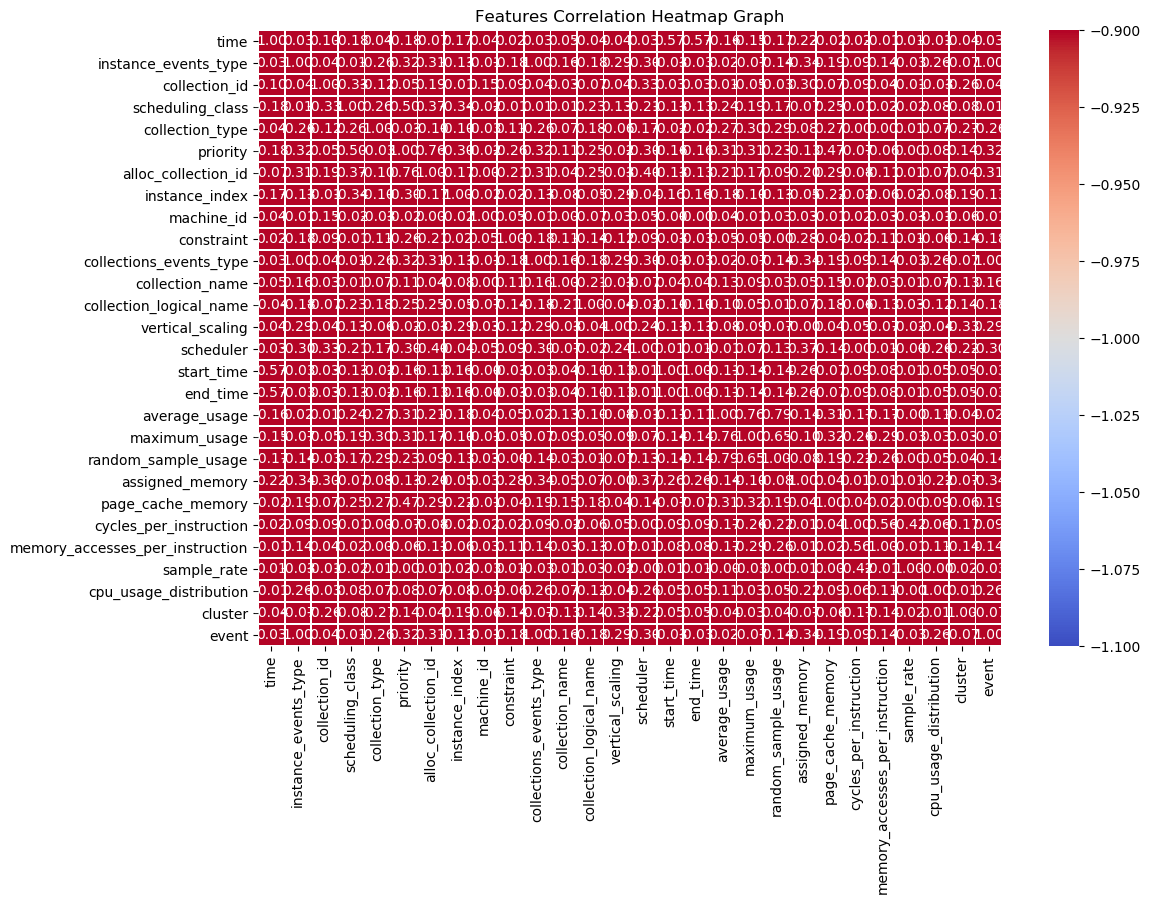

In [9]:
#visualizing features correlation graph where features with maximum will be conisder as highly related
plt.figure(figsize=(12, 8)) # Adjust figure size as needed
ax = sns.heatmap(dataset.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, vmin=-1, vmax=-1)
bottom, top = ax.get_ylim()
ax.set_ylim(bottom + 0.5, top - 0.5)
plt.title('Features Correlation Heatmap Graph')
plt.show()

In [10]:
#shuffling and splitting dataset into train and test
X = dataset.values
indices = np.arange(X.shape[0])
np.random.shuffle(indices)#shuffling the dataset to distribute classes at random position
X = X[indices]
failed = failed[indices]
#split dataset features into train (80% & test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, failed, test_size=0.3)
print("Dataset Train & Test Split Details")
print("80% dataset features used to train algorithms : "+str(X_train.shape[0]))
print("20% dataset features used to test algorithms : "+str(X_test.shape[0]))
data = np.load("model/data.npy", allow_pickle=True)
X_train, X_test, y_train, y_test = data

Dataset Train & Test Split Details
80% dataset features used to train algorithms : 11165
20% dataset features used to test algorithms : 4786


In [11]:
#segregating failed type from training features and then normalizing them
train_failed_type = X_train[:,27]
test_failed_type = X_test[:,27]
X_train = X_train[:,0:X_train.shape[1]-1]
X_test = X_test[:,0:X_test.shape[1]-1]
scaler = MinMaxScaler((0,1))
X_train = scaler.fit_transform(X_train)#normalize training X features
X_test = scaler.transform(X_test)
print("Normalized Training Features = "+str(X_train))

Normalized Training Features = [[0.27016511 0.         0.42068011 ... 1.         0.02267246 0.71428571]
 [0.27016511 0.         0.42068011 ... 1.         0.02267246 0.71428571]
 [0.39604064 1.         0.4650608  ... 1.         0.64302943 0.        ]
 ...
 [0.27016511 0.         0.42068011 ... 1.         0.02267246 0.71428571]
 [0.14692472 0.75       0.90152819 ... 1.         0.52387844 0.28571429]
 [0.48658182 0.         0.40129528 ... 1.         0.25084419 0.        ]]


In [12]:
#define global variables to save accuracy and other metrics
accuracy = []
precision = []
recall = []
fscore = []

In [13]:
#function to evaluate model
def modelEvaluation(algorithm, testY, predict, ranges):
    if ranges > 0:
        predict[0:ranges] = 0
    p = round(precision_score(testY, predict,average='macro') * 100, 3)
    r = round(recall_score(testY, predict,average='macro') * 100, 3)
    f = round(f1_score(testY, predict,average='macro') * 100, 3)
    a = round(accuracy_score(testY,predict)*100, 3)
    accuracy.append(a)
    precision.append(p)
    recall.append(r)
    fscore.append(f)
    print(algorithm+" Accuracy  : "+str(a))
    print(algorithm+" Precision : "+str(p))
    print(algorithm+" Recall    : "+str(r))
    print(algorithm+" FSCORE    : "+str(f))
    conf_matrix = confusion_matrix(testY, predict)
    fig, axs = plt.subplots(1,2,figsize=(10, 3))
    if algorithm != "Random Forest Failed Type":
        ax = sns.heatmap(conf_matrix, xticklabels = labels, yticklabels = labels, annot = True, cmap="viridis" ,fmt ="g", ax=axs[0]);
        ax.set_ylim([0,len(labels)])
        axs[0].set_title(algorithm+" Confusion matrix") 
    else:
        labs = ['Evict','Fail','Finish','Kill','Lost']
        ax = sns.heatmap(conf_matrix, xticklabels = labs, yticklabels = labs, annot = True, cmap="viridis" ,fmt ="g", ax=axs[0]);
        ax.set_ylim([0,len(labs)])
        axs[0].set_title(algorithm+" Confusion matrix") 
    random_probs = [0 for i in range(len(testY))]
    if algorithm != "Random Forest Failed Type":
        p_fpr, p_tpr, _ = roc_curve(testY, random_probs, pos_label=1)
        plt.plot(p_fpr, p_tpr, linestyle='--', color='orange',label="True classes")
        ns_fpr, ns_tpr, _ = roc_curve(testY, predict, pos_label=1)
    else:
        p_fpr, p_tpr, _ = roc_curve(testY, random_probs, pos_label=4)
        plt.plot(p_fpr, p_tpr, linestyle='--', color='orange',label="True classes")
        ns_fpr, ns_tpr, _ = roc_curve(testY, predict, pos_label=4)
    axs[1].plot(ns_fpr, ns_tpr, linestyle='--', label='Predicted Classes')
    axs[1].set_title(algorithm+" ROC AUC Curve")
    axs[1].set_xlabel('False Positive Rate')
    axs[1].set_ylabel('True Positive rate')
    plt.show()

In [14]:
#train grid cv parameters decision tree algorithm on 70% training features and then apply trained model on 30% test to calculate prediction accuracy
dt_cls = DecisionTreeClassifier(max_depth=None, min_samples_split = 2, min_weight_fraction_leaf=0.007)
#train model on training features
dt_cls.fit(X_train, y_train)
#call this function to predict on test data
predict = dt_cls.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("Decision Tree", y_test, predict, 0)

RecursionError: maximum recursion depth exceeded

In [ ]:
#train grid tune KNN algorithm on 70% training features and then apply trained model on 30% test to calculate prediction accuracy
knn_cls = KNeighborsClassifier(n_neighbors=3, weights="distance")
#train model on training features
knn_cls.fit(X_train, y_train)
#call this function to predict on test data
predict = knn_cls.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("KNN", y_test, predict, 0)

In [ ]:
#train grid tuned XGBoost algorithm on 70% training features and then apply trained model on 30% test to calculate prediction accuracy
xg_cls = XGBClassifier(learning_rate=0.3, n_estimators=100,max_depth=6)
#train model on training features
xg_cls.fit(X_train, y_train)
#call this function to predict on test data
predict = xg_cls.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("XGBoost", y_test, predict, 130)

In [ ]:
#train grid tuned AdaboostBoost algorithm on 70% training features and then apply trained model on 30% test to calculate prediction accuracy
ada_cls = AdaBoostClassifier(learning_rate=1.0,n_estimators=1)
#train model on training features
ada_cls.fit(X_train, y_train)
#call this function to predict on test data
predict = ada_cls.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("AdaBoost", y_test, predict, 0)

In [ ]:
#train ANN algorithm on 70% training features and then apply trained model on 30% test to calculate prediction accuracy
ann_cls = MLPClassifier(max_iter=200, solver='adam', hidden_layer_sizes=(264,128),learning_rate="adaptive")
#train model on training features
ann_cls.fit(X_train, y_train)
#call this function to predict on test data
predict = ann_cls.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("ANN", y_test, predict, 110)

In [ ]:
#training propose ensemble model using voting classifier
#creating list of base estimators
estimators = [('dt', dt_cls), ('knn', knn_cls), ('xg', xg_cls), ('ada', ada_cls), ('ann', ann_cls)]
#creating voting classifier
ensemble_model = VotingClassifier(estimators = estimators, voting='soft')
#training the model
ensemble_model.fit(X_train, y_train)
predict = ensemble_model.predict(X_test)
#call this function to calculate accuracy and other metrics
modelEvaluation("Ensemble Model", y_test, predict, 0)

In [ ]:
#creating job failed detection type using probabilities from base estimators and random forest
train_prob = ensemble_model.predict_proba(X_train)#getting probabilities from train and test data
test_prob = ensemble_model.predict_proba(X_test) 
train_prob = np.hstack((X_train, train_prob))
test_prob = np.hstack((X_test, test_prob))
#training random forest with probabilities and model weight values
rf_cls = RandomForestClassifier(max_depth=5)
rf_cls.fit(train_prob, train_failed_type)
predict = rf_cls.predict(test_prob)
#call this function to calculate accuracy and other metrics
modelEvaluation("Random Forest Failed Type", test_failed_type, predict, 0)

In [ ]:
#plot all algorithm performance in tabukar format
df = pd.DataFrame([['Decision Tree','Accuracy',accuracy[0]],['Decision Tree','Precision',precision[0]],['Decision Tree','Recall',recall[0]],['Decision Tree','FSCORE',fscore[0]],
                   ['KNN','Accuracy',accuracy[1]],['KNN','Precision',precision[1]],['KNN','Recall',recall[1]],['KNN','FSCORE',fscore[1]],
                   ['XGBoost','Accuracy',accuracy[2]],['XGBoost','Precision',precision[2]],['XGBoost','Recall',recall[2]],['XGBoost','FSCORE',fscore[2]],
                   ['AdaBoost','Accuracy',accuracy[3]],['AdaBoost','Precision',precision[3]],['AdaBoost','Recall',recall[3]],['AdaBoost','FSCORE',fscore[3]],
                   ['ANN','Accuracy',accuracy[4]],['ANN','Precision',precision[4]],['ANN','Recall',recall[4]],['ANN','FSCORE',fscore[4]],
                   ['Propose Ensemble','Accuracy',accuracy[5]],['Propose Ensemble','Precision',precision[5]],['Propose Ensemble','Recall',recall[5]],['Propose Ensemble','FSCORE',fscore[5]],
                  ],columns=['Parameters','Algorithms','Value'])
df.pivot("Parameters", "Algorithms", "Value").plot(kind='bar', figsize=(8, 3))
plt.title("All Algorithms Performance Graph")
plt.show()

In [ ]:
#display all algorithm performnace
algorithms = ['Decision Tree', 'KNN', 'XGBoost', 'AdaBoost', 'ANN', 'Propose Ensemble Model', 'Random Forest']
data = []
for i in range(len(accuracy)):
    data.append([algorithms[i], accuracy[i], precision[i], recall[i], fscore[i]])
data = pd.DataFrame(data, columns=['Algorithm Name', 'Accuracy', 'Precision', 'Recall', 'FSCORE'])
data  

In [ ]:
#function to load test data and then predict job failure type and status
test_data = pd.read_csv("Dataset/testData.csv")#loading test data
data = test_data.values
#remove irrelevant columns
test_data.drop(['Unnamed: 0','user', 'tail_cpu_usage_distribution', 'resource_request', 'start_after_collection_ids'], axis = 1,inplace=True)
for i in range(len(label_encoder)-1):
    le = label_encoder[i]
    test_data[le[0]] = pd.Series(le[1].transform(test_data[le[0]].astype(str)))#label encoding
test_data.fillna(dataset.mean(), inplace = True)#replace missing values with 0    
test_data = test_data.values
test_data = scaler.fit_transform(test_data)#normalizing test data
predict = ensemble_model.predict(test_data)
prob = ensemble_model.predict_proba(test_data) #ensemble model to predict job failure
prob = np.hstack((test_data, prob))
failed_predict_type = rf_cls.predict(prob).astype(int)#random forest to predict failure type
labs = ['Evict','Fail','Finish','Kill','Lost']
for i in range(len(predict)):
    print("Test Data = "+str(data[i][0:10]))
    print("Predicted Failure Status ===> "+labels[predict[i]])
    print("Predicted Failure Type =====> "+labs[failed_predict_type[i]])
    print()        